# 01 · Helmholtz modelling on CPU and GPU
### Marmousi, complex pressure, PML and checked solver agreement

## Goal
Build frequency-domain acoustic data from the **complete bundled Marmousi model**, inspect a physical wavefield, and compare sparse direct and matrix-free solvers on a smaller Marmousi crop. The same tensor solver runs on CPU or CUDA; the CUDA section explicitly reports **unrun** when no GPU is available.

The default uses 2 Hz, five sources, double precision and a single CPU thread. It is a bounded teaching example, not a high-frequency performance benchmark. No cell creates a cloud instance or incurs provider charges. Typical CPU execution takes tens of seconds or less; actual timings are measured below.

**Learning path:** SI model → source/receiver geometry → dispersion screen → PML Helmholtz solve → receiver data → CPU/CUDA agreement.

## Setup
Run from a checkout using the environment in the [README](../README.md), then install notebook support with `python -m pip install -c requirements/fwi2d-py312.lock -e '.[fwi2d,notebooks]'` and select that Python kernel. The notebook discovers the checkout from its current directory or an ancestor; opening it from the repository root or `notebooks/` works. Data are read locally without modification or download.

All coordinates are **metres**, velocity is **m/s**, and frequency is **Hz**. Arrays use `[z, x]`; depth increases downward. With the convention $p(\mathbf{x},t)=\Re\{u(\mathbf{x})e^{-i\omega t}\}$,

$$[\nabla^2 + \omega^2m(\mathbf{x})]u=q,\qquad m=v^{-2},\quad \omega=2\pi f.$$

The normalized discrete point source integrates to one: its nodal amplitude is $1/(\Delta z\Delta x)$. Pressure is reported in **normalized source units**, not calibrated pascals.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import os
import platform
import sys
import tempfile
import time

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "simplefwi-mpl"))
os.environ.setdefault("XDG_CACHE_HOME", str(Path(tempfile.gettempdir()) / "simplefwi-cache"))
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from simplefwi.fwi2d import (
    AcousticFWI, Acquisition, BoundaryConfig, Grid2D, SolverConfig,
    assess_dispersion, load_marmousi,
)

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/marmousi.mat").is_file()
             and (p / "simplefwi/fwi2d").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the SimpleFWI checkout or notebooks/ directory.")

torch.set_num_threads(1)
torch.manual_seed(17)
np.random.seed(17)
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10, "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    "savefig.facecolor": "white",
})
COLORS = {"direct": "#1b6ca8", "fgmres": "#bc4b1f", "cuda": "#357c54"}
notebook_started = time.perf_counter()
runtime = {"python": platform.python_version(), "kernel_executable": sys.executable, "torch": str(torch.__version__),
           "cpu_threads": torch.get_num_threads(), "real_dtype": "float64",
           "complex_dtype": "complex128", "cuda_available": torch.cuda.is_available(),
           "torch_cuda_build": torch.version.cuda}
display(pd.Series(runtime, name="Runtime").to_frame())

,Runtime
python,3.12.14
kernel_executable,/workspace/SimpleFWI/.venv/bin/python
torch,2.12.0+cpu
cpu_threads,1
real_dtype,float64
complex_dtype,complex128
cuda_available,False
torch_cuda_build,None


## Steps
### 1. Load the complete model and declare the experiment
The loader requires the velocity unit explicitly; it never infers units from magnitudes. The hash below identifies the exact bundled MATLAB input. Its original coordinates include a nonzero horizontal origin, which we retain.

`FREE_SURFACE = True` replaces the top PML with zero pressure on the top physical row. Sources and receivers remain below that row. This changes the physical experiment, so rerun every subsequent cell after changing it.

In [2]:
DATASET = ROOT / "data/marmousi.mat"
grid, velocity = load_marmousi(DATASET, velocity_unit="m/s")
FREQUENCY_HZ = 2.0
FREE_SURFACE = False
boundary = BoundaryConfig(top="free_surface" if FREE_SURFACE else "pml",
                          pml_cells=32, sigma_max=60.0, alpha=0.0)
z0, x0 = grid.origin_m
dz, dx = grid.spacing_m
z = z0 + np.arange(grid.shape[0]) * dz
x = x0 + np.arange(grid.shape[1]) * dx
source_columns = np.linspace(12, grid.shape[1] - 13, 5, dtype=int)
source_positions = tuple((float(z[1]), float(x[j])) for j in source_columns)
receiver_positions = tuple((float(z[2]), float(x[j])) for j in range(1, grid.shape[1] - 1))
acquisition = Acquisition(source_positions, receiver_positions)
provenance = {"dataset": str(DATASET.relative_to(ROOT)),
              "sha256": hashlib.sha256(DATASET.read_bytes()).hexdigest(),
              "declared_velocity_unit": "m/s", "shape_z_x": grid.shape,
              "spacing_z_x_m": grid.spacing_m, "origin_z_x_m": grid.origin_m,
              "velocity_range_m_s": [float(velocity.min()), float(velocity.max())]}
print(json.dumps(provenance, indent=2))
print(f"{len(source_positions)} sources × {len(receiver_positions)} receivers at {FREQUENCY_HZ:g} Hz")

{
  "dataset": "data/marmousi.mat",
  "sha256": "6756a104e3e5eb641ba4ba05c7fb983978e13c9885fac87c4909e51a79cad572",
  "declared_velocity_unit": "m/s",
  "shape_z_x": [
    121,
    373
  ],
  "spacing_z_x_m": [
    25.0,
    25.0
  ],
  "origin_z_x_m": [
    0.0,
    -200.0
  ],
  "velocity_range_m_s": [
    1466.0417103759814,
    5928.193453359496
  ]
}
5 sources × 371 receivers at 2 Hz


### 2. Understand the padded PML domain
PML adds computational nodes **outside** the physical model. It applies the coordinate stretch $s_j=1+i\sigma_j/\omega$, with a cubic damping profile. The conservative discrete operator represents

$$\partial_x\!\left(\frac{s_z}{s_x}\partial_xu\right)
+\partial_z\!\left(\frac{s_x}{s_z}\partial_zu\right)
+\omega^2s_xs_zm\,u=q.$$

The outermost padded nodes have zero pressure; the physical/PML interface does not. The physical model extends into PML by its nearest boundary values. The alternative pressure-release surface removes top padding and sets $u=0$ at the physical surface. This implementation uses ordinary PML (`alpha=0`), not an absorbing boundary condition or an implemented C-PML variant.

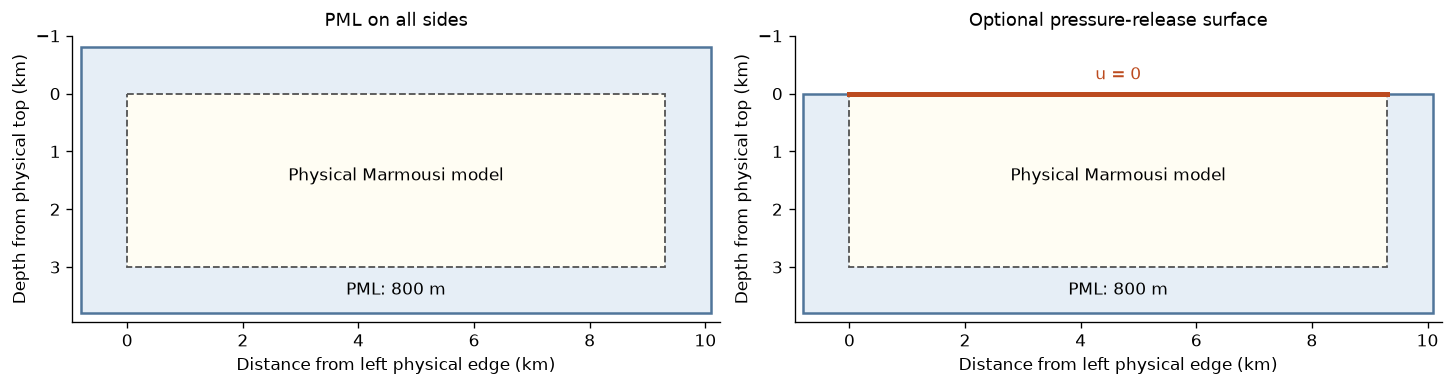

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
pad_km = boundary.pml_cells * dx / 1000
width_km, depth_km = (x[-1] - x[0]) / 1000, (z[-1] - z[0]) / 1000
for ax, free, title in zip(axes, (False, True), ("PML on all sides", "Optional pressure-release surface")):
    top = 0 if free else -pad_km
    ax.add_patch(Rectangle((-pad_km, top), width_km + 2 * pad_km,
                           depth_km + pad_km - top, facecolor="#e6eef6",
                           edgecolor="#50759a", linewidth=1.5))
    ax.add_patch(Rectangle((0, 0), width_km, depth_km, facecolor="#fffdf3",
                           edgecolor="#555555", linestyle="--", linewidth=1.1))
    if free:
        ax.plot([0, width_km], [0, 0], color="#bc4b1f", lw=3)
        ax.text(width_km / 2, -0.18, "u = 0", ha="center", va="bottom", color="#bc4b1f")
    ax.text(width_km / 2, depth_km / 2, "Physical Marmousi model", ha="center")
    ax.text(width_km / 2, depth_km + pad_km / 2, "PML: 800 m", ha="center", va="center")
    ax.set(xlim=(-pad_km - 0.15, width_km + pad_km + 0.15),
           ylim=(depth_km + pad_km + 0.15, -pad_km - 0.2),
           xlabel="Distance from left physical edge (km)", ylabel="Depth from physical top (km)", title=title)
    ax.set_aspect("equal")
plt.show()

### 3. Screen spatial dispersion before solving
For the second-order stencil, the screen bounds the local homogeneous phase-wavenumber error at the **minimum allowed velocity**. We request a 1% limit and reject a failing setup instead of silently changing its frequency or grid.

This is a spatial screen, not proof of heterogeneous-model accuracy or PML reflection performance. The full Marmousi PML has not been independently calibrated. Its 800 m thickness is deliberate, but the passing solve residual below cannot validate that choice.

,frequency (Hz),maximum local phase error (%),screened frequency ceiling (Hz),minimum allowed velocity (m/s),PML thickness (m),screen passed
0,2.0,0.21101,4.30803,1400.0,800.0,True


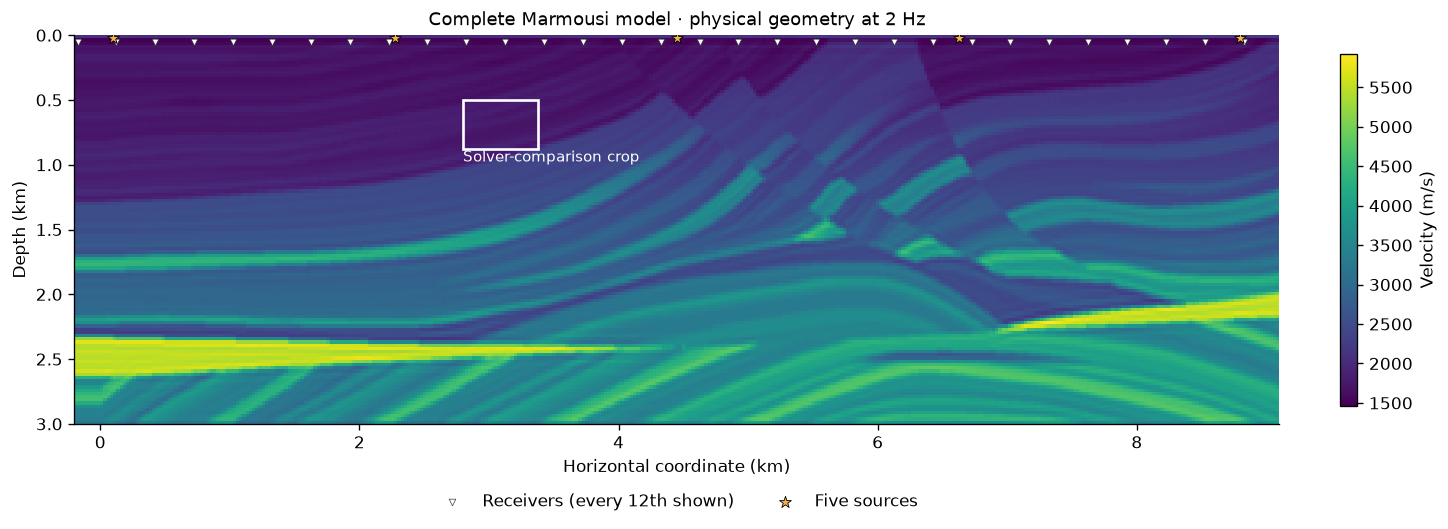

In [4]:
dispersion = assess_dispersion(grid, (1400.0, 6500.0), (FREQUENCY_HZ,), max_phase_error=0.01)
assert dispersion.passed, "Refine the grid or explicitly choose a lower frequency before solving."
display(pd.DataFrame([{
    "frequency (Hz)": FREQUENCY_HZ,
    "maximum local phase error (%)": 100 * dispersion.max_phase_error,
    "screened frequency ceiling (Hz)": dispersion.frequency_ceiling_hz,
    "minimum allowed velocity (m/s)": dispersion.minimum_velocity_m_s,
    "PML thickness (m)": boundary.pml_cells * dx,
    "screen passed": dispersion.passed,
}]).round(5))

# This crop is used later only for a bounded solver comparison.
CROP_Z, CROP_X = slice(20, 36), slice(120, 144)
fig, ax = plt.subplots(figsize=(12, 4.1), layout="constrained")
model_image = ax.imshow(velocity.numpy(), extent=(x[0]/1000, x[-1]/1000, z[-1]/1000, z[0]/1000),
                       origin="upper", aspect="equal", cmap="viridis")
ax.scatter(np.array(receiver_positions)[::12, 1]/1000, np.array(receiver_positions)[::12, 0]/1000,
           s=16, marker="v", color="white", edgecolors="#333333", linewidths=0.4,
           label="Receivers (every 12th shown)")
ax.scatter(np.array(source_positions)[:, 1]/1000, np.array(source_positions)[:, 0]/1000,
           s=55, marker="*", color="#f1b44c", edgecolors="black", linewidths=0.5, label="Five sources")
ax.add_patch(Rectangle((x[CROP_X.start]/1000, z[CROP_Z.start]/1000),
                       (CROP_X.stop-CROP_X.start-1)*dx/1000,
                       (CROP_Z.stop-CROP_Z.start-1)*dz/1000,
                       fill=False, edgecolor="white", linewidth=1.6))
ax.text(x[CROP_X.start]/1000, z[CROP_Z.stop-1]/1000 + 0.1, "Solver-comparison crop", color="white", fontsize=9)
ax.set(title="Complete Marmousi model · physical geometry at 2 Hz", xlabel="Horizontal coordinate (km)", ylabel="Depth (km)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
fig.colorbar(model_image, ax=ax, label="Velocity (m/s)", shrink=0.88)
plt.show()

### 4. Simulate frequency-domain receiver data on CPU
`AcousticFWI.simulate` returns `[frequency, source, receiver]` complex data. Source batches limit live wavefields; the direct CPU solver reuses one sparse factorization across sources at fixed model and frequency. Its configured memory budget is an internal storage estimate, not a hard process RSS limit.

In [5]:
reference_config = SolverConfig(method="direct", device="cpu", dtype=torch.complex128,
                                rtol=1e-10, atol=1e-12, memory_budget_bytes=2 * 1024**3)
full_problem = AcousticFWI(grid, acquisition, boundary, reference_config)
started = time.perf_counter()
full_data = full_problem.simulate(velocity, (FREQUENCY_HZ,), source_batch_size=2)
full_seconds = time.perf_counter() - started
full_residual = max(report.relative_residual for report in full_problem.last_solve_reports)
assert full_data.shape == (1, 5, len(receiver_positions))
assert torch.isfinite(full_data).all()
assert all(report.converged for report in full_problem.last_solve_reports)
print(f"Full-domain data: shape={tuple(full_data.shape)}, elapsed={full_seconds:.3f} s")
print(f"Largest reported relative residual: {full_residual:.3e}")
print(f"Compact computational unknowns: {full_problem.operator.n_dof:,}")

Full-domain data: shape=(1, 5, 371), elapsed=1.407 s
Largest reported relative residual: 1.349e-14
Compact computational unknowns: 79,605


### 5. Inspect one physical wavefield and the receiver response
The high-level simulator discards batch wavefields after sampling. For a selected diagnostic, call the same solver explicitly and then extract the physical region. Avoid retaining every wavefield during a large sweep; use the bounded [recording API](../guides/outputs.md) for selected outputs.

We show the central source. Each map has the same physical aspect ratio; the real-pressure colour scale is symmetric about zero. The second map shows amplitude relative to this wavefield's maximum, clipped at −60 dB for readability.

Recomputed operator residual: 1.349e-14; sampler agreement: 0.000e+00


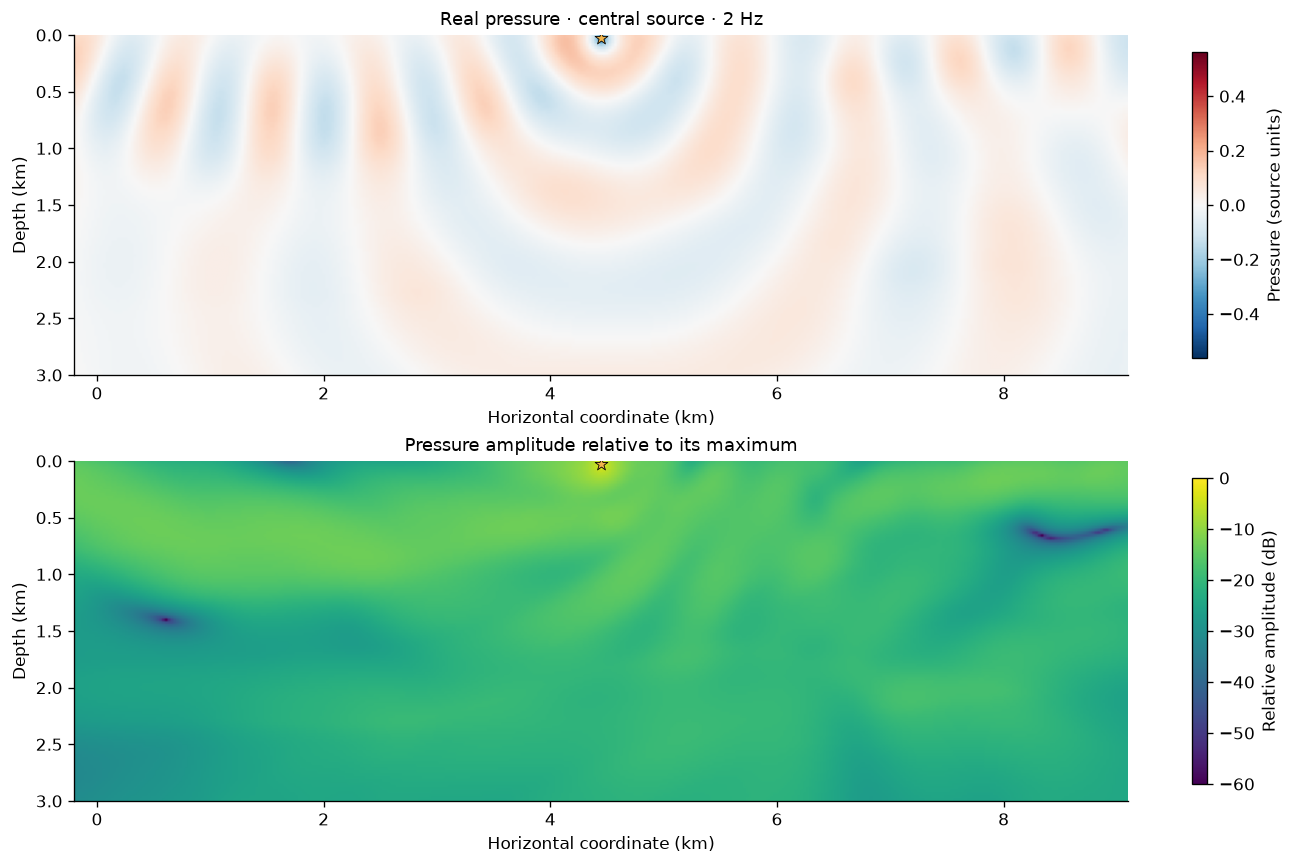

In [6]:
source_index = 2
source_amplitudes = torch.zeros(len(source_positions), dtype=torch.complex128)
source_amplitudes[source_index] = 1
rhs = full_problem.sources.source_rhs(source_amplitudes)
m = velocity.reciprocal().square()
omega = 2 * math.pi * FREQUENCY_HZ
with torch.no_grad():
    compact_wave, wave_report = full_problem.solver.solve(full_problem.operator, m, omega, rhs)
    physical_wave = full_problem.operator.physical(compact_wave)
    explicit_residual = float(torch.linalg.vector_norm(full_problem.operator.apply(m, omega, compact_wave) - rhs)
                              / torch.linalg.vector_norm(rhs))
    selected_data_error = float(torch.linalg.vector_norm(full_problem.receivers.sample(compact_wave) - full_data[0, source_index])
                                / torch.linalg.vector_norm(full_data[0, source_index]))
assert explicit_residual < 1e-10
assert selected_data_error < 1e-10
full_problem.solver.clear_cache()
print(f"Recomputed operator residual: {explicit_residual:.3e}; sampler agreement: {selected_data_error:.3e}")

real_wave = physical_wave.real.numpy()
amplitude = physical_wave.abs().numpy()
relative_db = 20 * np.log10(np.maximum(amplitude / amplitude.max(), 1e-3))
limit = np.abs(real_wave).max()
fig, axes = plt.subplots(2, 1, figsize=(12, 7.1), layout="constrained")
for ax, values, cmap, low, high, title, label in (
    (axes[0], real_wave, "RdBu_r", -limit, limit, "Real pressure · central source · 2 Hz", "Pressure (source units)"),
    (axes[1], relative_db, "viridis", -60, 0, "Pressure amplitude relative to its maximum", "Relative amplitude (dB)"),
):
    im = ax.imshow(values, extent=(x[0]/1000, x[-1]/1000, z[-1]/1000, z[0]/1000),
                   origin="upper", aspect="equal", cmap=cmap, vmin=low, vmax=high)
    ax.scatter(source_positions[source_index][1]/1000, source_positions[source_index][0]/1000,
               marker="*", s=65, color="#f1b44c", edgecolors="black", linewidths=0.5)
    ax.set(title=title, xlabel="Horizontal coordinate (km)", ylabel="Depth (km)")
    fig.colorbar(im, ax=ax, label=label, shrink=0.9)
plt.show()

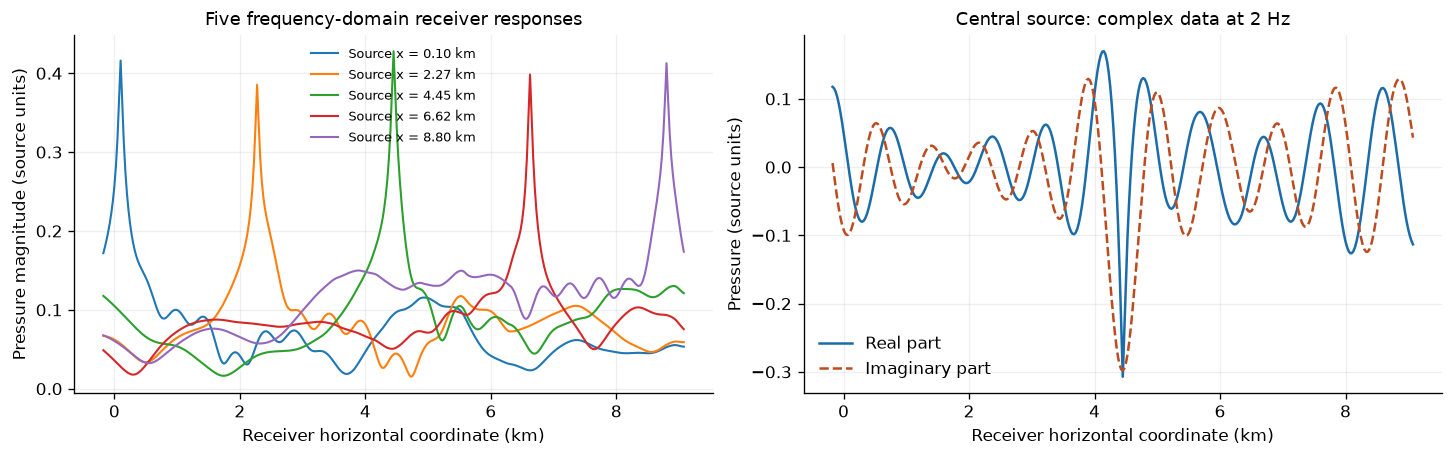

In [7]:
receiver_x_km = np.array(receiver_positions)[:, 1] / 1000
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), layout="constrained")
for i, source in enumerate(source_positions):
    axes[0].plot(receiver_x_km, full_data[0, i].abs().numpy(), lw=1.25,
                 label=f"Source x = {source[1]/1000:.2f} km")
axes[0].set(title="Five frequency-domain receiver responses", xlabel="Receiver horizontal coordinate (km)",
            ylabel="Pressure magnitude (source units)")
axes[0].legend(fontsize=8, frameon=False)
axes[1].plot(receiver_x_km, full_data[0, source_index].real.numpy(), color=COLORS["direct"], label="Real part")
axes[1].plot(receiver_x_km, full_data[0, source_index].imag.numpy(), color=COLORS["fgmres"], linestyle="--", label="Imaginary part")
axes[1].set(title="Central source: complex data at 2 Hz", xlabel="Receiver horizontal coordinate (km)",
            ylabel="Pressure (source units)")
axes[1].legend(frameon=False)
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

### 6. Compare sparse and matrix-free solvers on a bounded crop
The crop is a **separate local model**, not a portion of the full-model wavefield: its exterior is replaced by nearest-boundary extension and PML. It retains the original 25 m spacing and coordinates. Its 12-cell (300 m) PML is a small algebraic demonstration and has not been physically calibrated.

Both solvers see exactly the same crop, source, receiver positions, PML, precision and frequency. CPU direct uses a sparse LU factorization; FGMRES applies the operator as PyTorch tensors with a shifted-Helmholtz multigrid preconditioner. It does not construct a fine-grid dense matrix. These single cold solves include setup costs and are not a controlled speedup benchmark.

In [8]:
crop_velocity = velocity[CROP_Z, CROP_X].clone()
crop_grid = Grid2D(tuple(crop_velocity.shape), grid.spacing_m,
                   (float(z[CROP_Z.start]), float(x[CROP_X.start])))
cz0, cx0 = crop_grid.origin_m
crop_source = ((cz0 + dz, cx0 + 10 * dx),)
crop_receivers = tuple((cz0 + 2 * dz, cx0 + j * dx) for j in range(1, crop_grid.shape[1] - 1))
crop_acquisition = Acquisition(crop_source, crop_receivers)
crop_boundary = BoundaryConfig(top=boundary.top, pml_cells=12, sigma_max=60.0)
assert assess_dispersion(crop_grid, (1400.0, 6500.0), (FREQUENCY_HZ,)).passed


def run_crop(method, device):
    config = SolverConfig(method=method, device=device, dtype=torch.complex128,
                          rtol=1e-10, atol=1e-14, restart=40, maxiter=200,
                          memory_budget_bytes=256 * 1024**2)
    problem = AcousticFWI(crop_grid, crop_acquisition, crop_boundary, config)
    local_velocity = crop_velocity.to(device=device, dtype=torch.float64)
    local_m = local_velocity.reciprocal().square()
    local_rhs = problem.sources.source_rhs(torch.ones(1, dtype=torch.complex128, device=device))
    if device.startswith("cuda"):
        torch.cuda.synchronize()
    started = time.perf_counter()
    with torch.no_grad():
        wave, report = problem.solver.solve(problem.operator, local_m, omega, local_rhs)
        data = problem.receivers.sample(wave)
        relative_residual = float(torch.linalg.vector_norm(problem.operator.apply(local_m, omega, wave) - local_rhs)
                                  / torch.linalg.vector_norm(local_rhs))
    if device.startswith("cuda"):
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    # Move only selected detached diagnostics to CPU after timing the solve.
    physical = problem.operator.physical(wave).cpu()
    compact, data = wave.cpu(), data.cpu()
    problem.solver.clear_cache()
    assert report.converged and relative_residual <= 1.1e-10
    assert torch.isfinite(compact).all() and torch.isfinite(data).all()
    result = {"solver": method, "device": device, "seconds": elapsed,
              "iterations": report.iterations, "true relative residual": relative_residual}
    return result, compact, physical, data


cpu_direct, crop_reference_wave, crop_reference_physical, crop_reference_data = run_crop("direct", "cpu")
cpu_tensor, crop_tensor_wave, crop_tensor_physical, crop_tensor_data = run_crop("fgmres", "cpu")
comparison_rows = [cpu_direct, cpu_tensor]
relative_error = lambda candidate, reference: float(torch.linalg.vector_norm(candidate - reference)
                                                   / torch.linalg.vector_norm(reference))
cpu_tensor["wavefield relative error"] = relative_error(crop_tensor_wave, crop_reference_wave)
cpu_tensor["data relative error"] = relative_error(crop_tensor_data, crop_reference_data)
assert cpu_tensor["wavefield relative error"] < 1e-7
assert cpu_tensor["data relative error"] < 1e-7
display(pd.DataFrame(comparison_rows).fillna("reference").set_index(["solver", "device"]))

,,seconds,iterations,true relative residual,wavefield relative error,data relative error
solver,device,,,,,
direct,cpu,0.015655,1,3.162621e-15,reference,reference
fgmres,cpu,1.156186,115,8.689574e-11,0.0,0.0


### 7. Run the same tensor problem on CUDA when available
A CUDA-enabled PyTorch build and an accessible NVIDIA GPU are both required. This cell never substitutes a CPU solve for a requested GPU solve. If CUDA is available, solve failures or tolerance violations stop execution visibly. If CUDA is absent, the notebook continues with an explicit **unrun—not available** status, without fabricated GPU timings.

Double precision is intentional for this tutorial. FP32 or quantized arithmetic requires separate residual, derivative and accuracy checks; it is not an automatic optimization.

In [9]:
gpu_status = "unrun—not available"
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    print(f"CUDA device: {gpu_name}; PyTorch CUDA build: {torch.version.cuda}")
    cuda_tensor, cuda_wave, cuda_physical, cuda_data = run_crop("fgmres", "cuda:0")
    cuda_tensor["wavefield relative error"] = relative_error(cuda_wave, crop_reference_wave)
    cuda_tensor["data relative error"] = relative_error(cuda_data, crop_reference_data)
    assert cuda_tensor["wavefield relative error"] < 1e-7
    assert cuda_tensor["data relative error"] < 1e-7
    comparison_rows.append(cuda_tensor)
    gpu_status = "passed: bounded crop residual and CPU agreement"
    runtime["gpu_name"] = gpu_name
else:
    print("CUDA status: unrun—not available. No GPU timing or GPU validation result was produced.")
display(pd.DataFrame(comparison_rows).fillna("reference").set_index(["solver", "device"]))

CUDA status: unrun—not available. No GPU timing or GPU validation result was produced.


,,seconds,iterations,true relative residual,wavefield relative error,data relative error
solver,device,,,,,
direct,cpu,0.015655,1,3.162621e-15,reference,reference
fgmres,cpu,1.156186,115,8.689574e-11,0.0,0.0


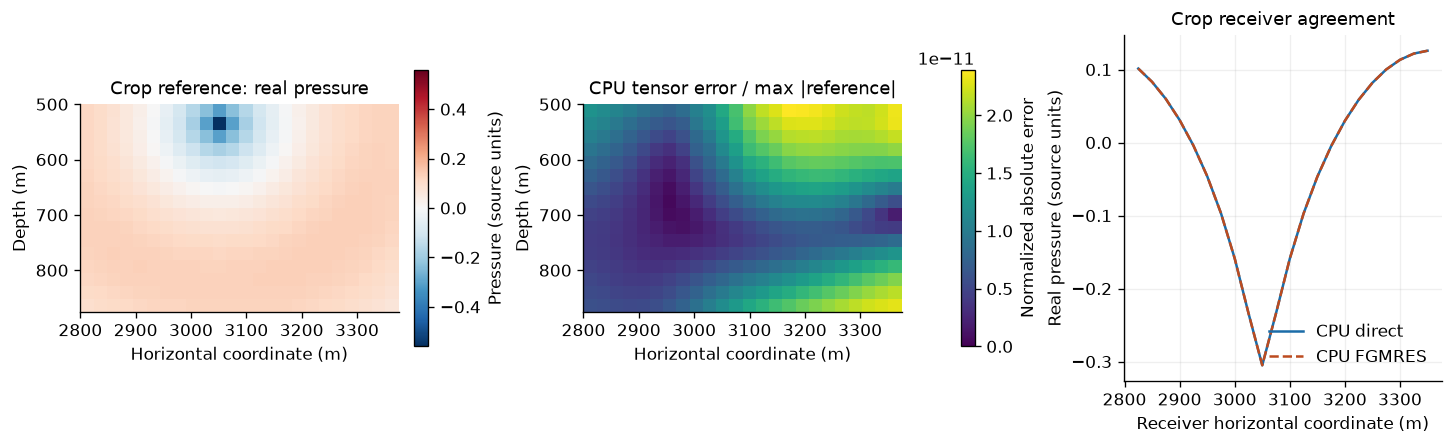

In [10]:
cz = cz0 + np.arange(crop_grid.shape[0]) * dz
cx = cx0 + np.arange(crop_grid.shape[1]) * dx
error = crop_tensor_physical - crop_reference_physical
error_scale = float(crop_reference_physical.abs().max())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
reference_real = crop_reference_physical.real.numpy()
real_limit = np.abs(reference_real).max()
im = axes[0].imshow(reference_real, extent=(cx[0], cx[-1], cz[-1], cz[0]), aspect="equal",
                    cmap="RdBu_r", vmin=-real_limit, vmax=real_limit)
axes[0].set(title="Crop reference: real pressure", xlabel="Horizontal coordinate (m)", ylabel="Depth (m)")
fig.colorbar(im, ax=axes[0], label="Pressure (source units)", shrink=0.8)
im = axes[1].imshow((error.abs()/error_scale).numpy(), extent=(cx[0], cx[-1], cz[-1], cz[0]),
                    aspect="equal", cmap="viridis", vmin=0)
axes[1].set(title="CPU tensor error / max |reference|", xlabel="Horizontal coordinate (m)", ylabel="Depth (m)")
fig.colorbar(im, ax=axes[1], label="Normalized absolute error", shrink=0.8)
receiver_x = np.array(crop_receivers)[:, 1]
axes[2].plot(receiver_x, crop_reference_data.real.numpy(), color=COLORS["direct"], label="CPU direct")
axes[2].plot(receiver_x, crop_tensor_data.real.numpy(), color=COLORS["fgmres"], linestyle="--", label="CPU FGMRES")
if torch.cuda.is_available():
    axes[2].plot(receiver_x, cuda_data.real.numpy(), color=COLORS["cuda"], marker="o", markersize=3,
                 markevery=3, linestyle="none", label="CUDA FGMRES")
axes[2].set(title="Crop receiver agreement", xlabel="Receiver horizontal coordinate (m)",
            ylabel="Real pressure (source units)")
axes[2].legend(frameon=False)
axes[2].grid(alpha=0.2)
plt.show()

## Checks
These checks answer different questions: the dispersion screen addresses the interior stencil; the recomputed residual tests the solved discrete equation; independent sparse/tensor agreement tests implementations of that equation. None establishes full Marmousi physical accuracy, maximum useful frequency, or a GPU speedup.

In [11]:
summary = {
    "dataset_sha256": provenance["sha256"],
    "full_model_shape": list(grid.shape), "frequency_hz": FREQUENCY_HZ,
    "top_boundary": boundary.top, "full_model_source_count": len(source_positions),
    "full_model_receiver_count": len(receiver_positions),
    "full_model_cpu_forward_seconds": full_seconds,
    "local_dispersion_screen_passed": dispersion.passed,
    "full_model_recomputed_relative_residual": explicit_residual,
    "full_model_selected_sampler_relative_error": selected_data_error,
    "crop_cpu_fgmres_wavefield_relative_error": cpu_tensor["wavefield relative error"],
    "crop_cpu_fgmres_data_relative_error": cpu_tensor["data relative error"],
    "cuda_status": gpu_status,
    "independent_full_model_accuracy": "unrun",
    "full_model_pml_reflection_calibration": "unrun",
    "notebook_elapsed_seconds": time.perf_counter() - notebook_started,
}
print(json.dumps(summary, indent=2, allow_nan=False))

{
  "dataset_sha256": "6756a104e3e5eb641ba4ba05c7fb983978e13c9885fac87c4909e51a79cad572",
  "full_model_shape": [
    121,
    373
  ],
  "frequency_hz": 2.0,
  "top_boundary": "pml",
  "full_model_source_count": 5,
  "full_model_receiver_count": 371,
  "full_model_cpu_forward_seconds": 1.406610090000072,
  "local_dispersion_screen_passed": true,
  "full_model_recomputed_relative_residual": 1.3488139912258378e-14,
  "full_model_selected_sampler_relative_error": 0.0,
  "crop_cpu_fgmres_wavefield_relative_error": 7.417107353544052e-11,
  "crop_cpu_fgmres_data_relative_error": 4.2922417985391524e-11,
  "cuda_status": "unrun\u2014not available",
  "independent_full_model_accuracy": "unrun",
  "full_model_pml_reflection_calibration": "unrun",
  "notebook_elapsed_seconds": 6.772882998
}


## Next Steps
- Continue with [Marmousi FWI and three native optimizers](02_fwi_marmousi_optimizers.ipynb), then [Camembert Hessians and uncertainty](03_camembert_hessian_uncertainty.ipynb).
- Try the free-surface option and rerun from the start. Compare the response as a different physical boundary condition, not an error against the all-PML result.
- Change source count or frequency explicitly, rerun screening, and calibrate PML against an independent enlarged-domain or refined reference before making physical accuracy claims. Refining a grid does not create new geological information.
- Read [accuracy](../guides/accuracy.md), [validation](../guides/validation.md) and [output recording](../guides/outputs.md) before a large run. Current FGMRES remains experimental at demanding high-frequency Marmousi scales; this tutorial establishes only the displayed bounded comparisons.